<a href="https://colab.research.google.com/github/zouhiraghenaim/Unsupervised---Learning-Algorithms/blob/main/TP09%20Hirarical_Clustering/TP9_02_Hirarical_Full_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Hirarical_Full_Clustering**

In [1]:
import pandas as pd
import numpy as np
from google.colab import files

In [2]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

In [3]:
upload=files.upload()

Saving hierarchical_model_dataset_500.csv to hierarchical_model_dataset_500.csv


In [10]:
df=pd.read_csv("hierarchical_model_dataset_500.csv",sep=";")
print(df.head())
df.shape

  Employee_ID Department_ID  Training_Hours  Experience_Years  \
0        E001           D01             9.0               6.4   
1        E002           D01            23.6              11.8   
2        E003           D01            15.4               3.4   
3        E004           D01            25.6               7.0   
4        E005           D01            30.3               5.2   

   Workload_Hours_Per_Week  Job_Satisfaction  Performance_Score  
0                     46.7              7.16              79.06  
1                     44.1              7.38              91.25  
2                     31.5              5.68              68.92  
3                     47.8              6.77              82.74  
4                     41.3              6.12              83.37  


(500, 7)

In [12]:
df.describe()


,Training_Hours,Experience_Years,Workload_Hours_Per_Week,Job_Satisfaction,Performance_Score
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,21.708600,7.560600,39.858200,7.210280,81.429100
std,6.489871,4.743909,6.086145,1.031601,9.275473
min,3.100000,0.500000,20.000000,4.450000,56.620000
25%,17.375000,4.075000,35.600000,6.537500,75.087500
50%,21.800000,6.600000,39.650000,7.215000,81.840000
75%,26.300000,9.900000,44.325000,7.902500,88.402500
max,40.700000,25.000000,59.800000,10.000000,100.000000


# **Isolate the clustering features:**

In [13]:
# Set Employee_ID as the index
df_clustering = df.set_index('Employee_ID')

# Drop Department_ID to leave only numerical features for the model
features = df_clustering.drop(columns=['Department_ID'])
features.head()

,Training_Hours,Experience_Years,Workload_Hours_Per_Week,Job_Satisfaction,Performance_Score
Employee_ID,,,,,
E001,9.0,6.4,46.7,7.16,79.06
E002,23.6,11.8,44.1,7.38,91.25
E003,15.4,3.4,31.5,5.68,68.92
E004,25.6,7.0,47.8,6.77,82.74
E005,30.3,5.2,41.3,6.12,83.37


### **2.Standardize the numerical scales:**

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
scaled_features



array([[-1.96018197, -0.24489556,  1.12528581, -0.04878857, -0.25567134],
       [ 0.29173065,  0.89454611,  0.69765813,  0.16468567,  1.05986351],
       [-0.97304219, -0.8779187 , -1.37469144, -1.48488799, -1.34997186],
       ...,
       [-0.03217459, -0.60360867,  1.0266025 , -1.78569259, -1.86150879],
       [ 1.77244032, -0.92012025,  1.12528581,  0.44608353, -0.141277  ],
       [ 2.43567486,  0.59913531, -0.38785831,  0.20349917,  1.523916  ]],
      shape=(500, 5))

# **3.Plot the Dendrogram:**

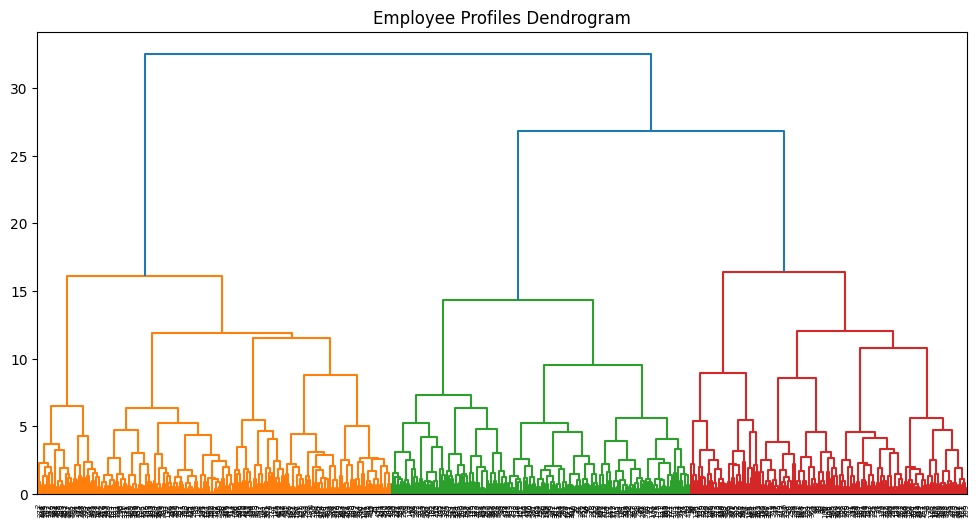

In [16]:
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.title("Employee Profiles Dendrogram")

# Create the dendrogram using the scaled data
dendrogram = sch.dendrogram(sch.linkage(scaled_features, method='ward'))
plt.show()

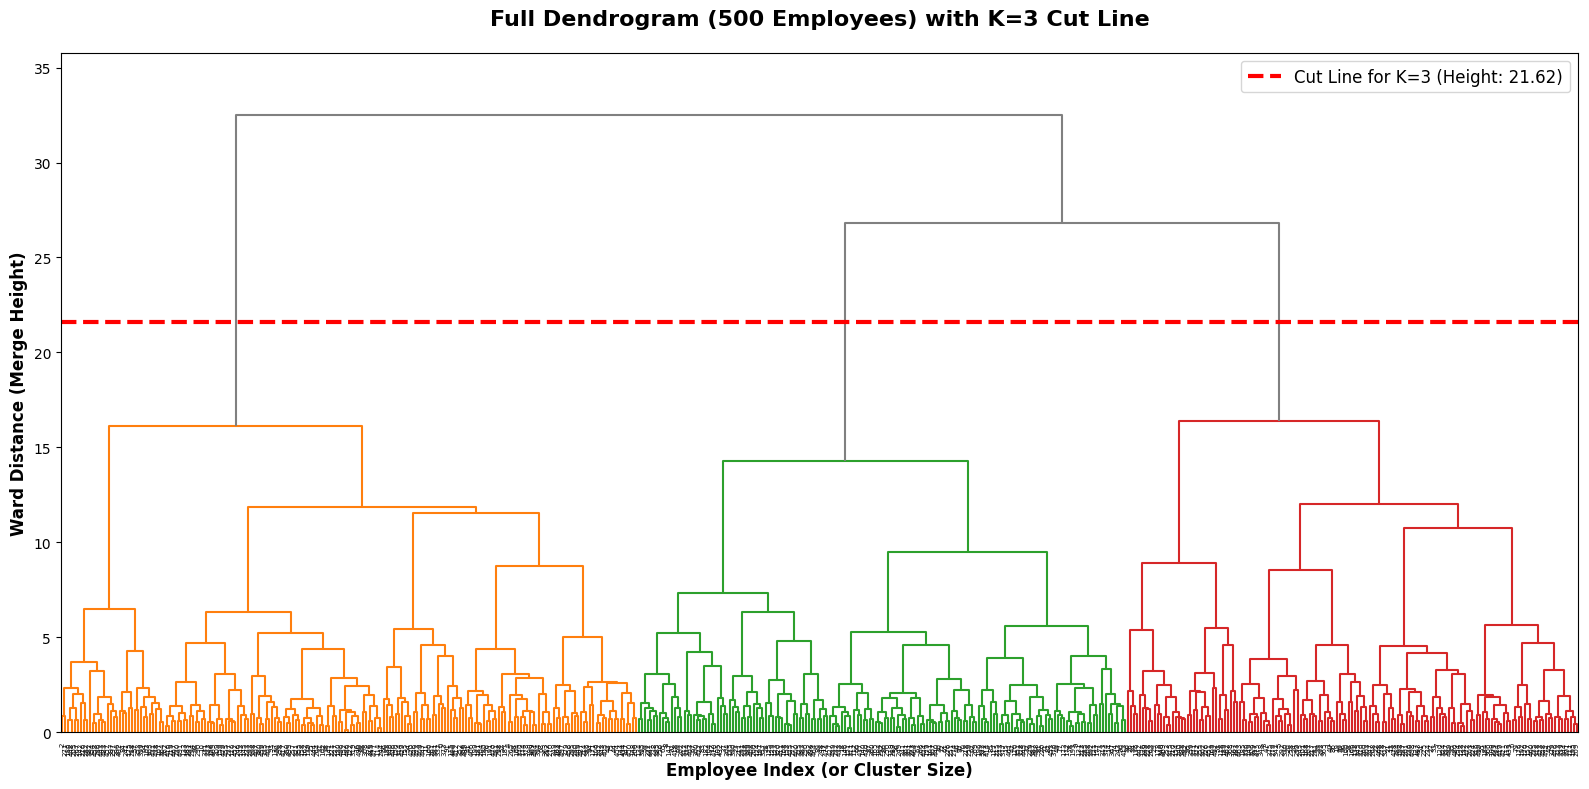

In [24]:
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
import numpy as np

# 1. Set up the figure size (wide enough for 500 data points)
plt.figure(figsize=(16, 8))

# 2. Calculate the linkage matrix
Z = sch.linkage(scaled_features, method='ward')

# 3. Calculate the exact height to cut the tree for K=3
height_k3 = (Z[-3, 2] + Z[-2, 2]) / 2

# 4. Plot the full Dendrogram
# color_threshold=height_k3 automatically colors the 3 clusters below this line
dendro = sch.dendrogram(
    Z,
    color_threshold=height_k3, # This creates the 3 colored clusters
    above_threshold_color='grey',
    leaf_rotation=90.,
    leaf_font_size=5.,         # Very small font because there are 500 labels
    show_leaf_counts=True
)

# 5. Draw the Cut Line for K=3
plt.axhline(
    y=height_k3,
    color='red',
    linestyle='--',
    linewidth=3,
    label=f'Cut Line for K=3 (Height: {height_k3:.2f})'
)

# 6. Formatting
plt.title('Full Dendrogram (500 Employees) with K=3 Cut Line', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Employee Index (or Cluster Size)', fontsize=12, fontweight='bold')
plt.ylabel('Ward Distance (Merge Height)', fontsize=12, fontweight='bold')
plt.legend(loc='upper right', fontsize=12)

# Adjust the y-axis limit slightly above the cut line so we can see the top
plt.ylim(0, Z[-1, 2] * 1.1)

plt.tight_layout()
plt.show()

# **4.Apply Agglomerative Clustering:**

In [20]:
from sklearn.cluster import AgglomerativeClustering

# Train the model (replace 3 with the number of clusters you see in the dendrogram)
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')

# Assign the resulting clusters back to your main dataframe
df['Cluster_Label'] = hc.fit_predict(scaled_features)

# View the average stats for each employee cluster
print(df.groupby('Cluster_Label')[['Training_Hours', 'Experience_Years', 'Workload_Hours_Per_Week', 'Job_Satisfaction', 'Performance_Score']].mean())

               Training_Hours  Experience_Years  Workload_Hours_Per_Week  \
Cluster_Label                                                              
0                   27.886577         11.408725                42.252349   
1                   17.609474          5.846316                42.737895   
2                   20.828571          6.022360                34.244099   

               Job_Satisfaction  Performance_Score  
Cluster_Label                                       
0                      7.532349          88.929597  
1                      6.572895          74.319579  
2                      7.664410          82.877764  


## **CLUSTER INTERPRETATION**


---
Based on the average metrics of each cluster, we can group the employees into three distinct profiles:

1. **Cluster 0: High-Performing Experienced Veterans**
   - Highest Training Hours (~27.9 hours)
   - Highest Experience (~11.4 years)
   - High Workload (~42.3 hours/week)
   - High Job Satisfaction (~7.5)
   - Highest Performance Score (~88.9)
   *Interpretation*: These are experienced senior employees who take on significant responsibilities and training. They are highly satisfied and represent the highest performers in the organization.

**2.Cluster 1: Highly Loaded, Low-Performing Under-Satisfied Juniors**
   - Lowest Training Hours (~17.6 hours)
   - Lowest Experience (~5.8 years)
   - Highest Workload (~42.7 hours/week)
   - Lowest Job Satisfaction (~6.6)
   - Lowest Performance Score (~74.3)
   *Interpretation*: This is a critical group of junior staff. They are facing high workloads with the lowest levels of training and support, resulting in the lowest job satisfaction and lower overall performance scores.

3.**Cluster 2: Well-Balanced, Satisfied Core Contributors**
   - Moderate Training Hours (~20.8 hours)
   - Moderate/Lower Experience (~6.0 years)
   - Lowest Workload (~34.2 hours/week)
   - Highest Job Satisfaction (~7.7)
   - Strong Performance Score (~82.9)
   *Interpretation*: These employees enjoy the best work-life balance (lowest workload) which directly correlates with their high job satisfaction. They consistently deliver strong, above-average performance.
